# Predicting Yelp Star Ratings with RoBERTa: Evaluation and Error Analysis

**Task:** 5-class star-rating prediction from review text (customer feedback analytics).
**Model:** `FacebookAI/roberta-base` fine-tuned with Hugging Face Transformers.
**Data:** `Yelp/yelp_review_full` (1 to 5 stars). The Hugging Face card lists 650,000 train and 50,000 test rows and a Yelp license ("other"). Check the Yelp terms before reuse. This repository does not include any review text.
**Baseline:** TF-IDF + logistic regression, so the transformer score has something to be compared against.

## What the notebook covers
| Step | Section |
|---|---|
| Setup, stratified sampling, cleaning | 1 and 2 |
| TF-IDF baseline | 3 |
| RoBERTa fine-tuning | 4 |
| Quantitative evaluation (accuracy, macro-F1 with bootstrap CI, star error) | 5 |
| Error analysis by length, contrast words, negation, truncation | 6 |
| Manual error review sample | 7 |
| SQL layer and dashboard export | 8 |
| Limitations and ethics | 9 |
| Open research question | 10 |
| Reproducibility record | 11 |

## How to run
1. Use a machine with a CUDA GPU if possible. On CPU, training is very slow.
2. Run all cells from top to bottom. Seeds are fixed (`SEED = 42`).
3. `DRY_RUN = True` runs the pipeline on tiny synthetic data and a tiny random model to check that the code works. Its numbers mean nothing. Keep it `False` for real results.
4. Everything the notebook writes goes to `outputs/`. Review text appears in some of those files, so `outputs/` is git-ignored. The committed results are in `results/`.

## 1. Setup and configuration

In [1]:
# %pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn scipy

import os, re, json, time, random, sqlite3, platform
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from datasets import load_dataset, Dataset
import transformers
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)

# ---- Configuration -------------------------------------------------------
SEED = 42
DRY_RUN = False                      # True = offline smoke test, numbers are meaningless
MODEL_NAME = "FacebookAI/roberta-base"
N_TRAIN_PER_CLASS = 4000             # 5 classes -> 20,000 training reviews
N_VAL_PER_CLASS = 400                # 2,000 validation reviews (disjoint from train)
N_TEST_PER_CLASS = 1000              # 5,000 test reviews (from the official test split)
MAX_LEN = 256                        # tokens; longer reviews are truncated (checked in Section 6)
EPOCHS = 2
LEARNING_RATE = 2e-5
TRAIN_BATCH = 16
EVAL_BATCH = 64
OUT_DIR = "outputs"
# --------------------------------------------------------------------------

if DRY_RUN:
    N_TRAIN_PER_CLASS, N_VAL_PER_CLASS, N_TEST_PER_CLASS, EPOCHS = 60, 12, 40, 1

os.makedirs(OUT_DIR, exist_ok=True)
set_seed(SEED)
STAR_NAMES = [f"{i} star" if i == 1 else f"{i} stars" for i in range(1, 6)]
use_cuda = torch.cuda.is_available()
use_bf16 = bool(use_cuda and torch.cuda.is_bf16_supported())
print("transformers", transformers.__version__, "| torch", torch.__version__)
print("CUDA:", use_cuda, "| GPU:", torch.cuda.get_device_name(0) if use_cuda else "none", "| bf16:", use_bf16)

W1118 23:50:28.935000 24392 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


transformers 5.23.0 | torch 2.11.0+cu128
CUDA: True | GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU | bf16: True


## 2. Data: stratified sample, cleaning, and checks

**Design decisions:**
- The full training split has 650,000 reviews. Training on all of it is not needed here, so I draw a **stratified random sample** (equal count per star) with a fixed seed.
- Validation rows are sampled from the training split and are **disjoint** from the training sample. Test rows come only from the official test split, so there is no train/test leakage.
- The test set is a stratified **subset** of the official test split. Results are a subset evaluation, not the full 50,000.
- Text cleaning is minimal. RoBERTa is case-sensitive, so I do not lowercase. The dataset card says newlines are stored as an escaped backslash-n, so I replace those with a space.

In [2]:
def stratified_indices(labels, n_per_class, rng, exclude=None):
    chosen = []
    for c in range(5):
        pool = np.where(labels == c)[0]
        if exclude is not None:
            pool = np.setdiff1d(pool, exclude)
        chosen.append(rng.choice(pool, size=n_per_class, replace=False))
    return np.sort(np.concatenate(chosen))

def make_synthetic(n_per_class, seed):
    # Only used when DRY_RUN is True: tiny fake reviews whose words loosely track the star rating.
    r = random.Random(seed)
    pos = ["great", "delicious", "friendly", "amazing", "perfect", "love", "fresh", "excellent"]
    neg = ["terrible", "rude", "cold", "awful", "slow", "bland", "dirty", "worst"]
    neu = ["the", "food", "place", "we", "ordered", "service", "table", "came", "was", "and", "with", "our", "menu", "waiter"]
    rows = []
    for star in range(5):
        for _ in range(n_per_class):
            words = r.choices(pos, k=star + r.randint(0, 1)) + r.choices(neg, k=4 - star + r.randint(0, 1))
            words += r.choices(neu, k=r.randint(5, 25))
            if r.random() < 0.3: words += ["but", "not"]
            r.shuffle(words)
            rows.append({"text": " ".join(words), "label": star})
    return pd.DataFrame(rows).sample(frac=1, random_state=seed).reset_index(drop=True)

if DRY_RUN:
    df_train = make_synthetic(N_TRAIN_PER_CLASS, SEED)
    df_val = make_synthetic(N_VAL_PER_CLASS, SEED + 1)
    df_test = make_synthetic(N_TEST_PER_CLASS, SEED + 2)
else:
    raw = load_dataset("Yelp/yelp_review_full")
    rng = np.random.default_rng(SEED)
    train_labels = np.array(raw["train"]["label"])
    test_labels = np.array(raw["test"]["label"])
    tr_idx = stratified_indices(train_labels, N_TRAIN_PER_CLASS, rng)
    va_idx = stratified_indices(train_labels, N_VAL_PER_CLASS, rng, exclude=tr_idx)
    te_idx = stratified_indices(test_labels, N_TEST_PER_CLASS, rng)
    assert len(set(tr_idx) & set(va_idx)) == 0, "train and validation overlap"
    df_train = raw["train"].select(tr_idx).to_pandas().sample(frac=1, random_state=SEED).reset_index(drop=True)
    df_val = raw["train"].select(va_idx).to_pandas().reset_index(drop=True)
    df_test = raw["test"].select(te_idx).to_pandas().reset_index(drop=True)

escaped_share = df_train["text"].str.contains(r"\\n", regex=True).mean()
print(f"Share of training reviews with an escaped newline before cleaning: {escaped_share:.1%}")
for d in (df_train, df_val, df_test):
    d["text"] = d["text"].str.replace(r"\\n", " ", regex=True).str.strip()

for name, d in [("train", df_train), ("validation", df_val), ("test", df_test)]:
    print(name, len(d), "rows | class counts:", d["label"].value_counts().sort_index().tolist())

Share of training reviews with an escaped newline before cleaning: 49.8%
train 20000 rows | class counts: [4000, 4000, 4000, 4000, 4000]
validation 2000 rows | class counts: [400, 400, 400, 400, 400]
test 5000 rows | class counts: [1000, 1000, 1000, 1000, 1000]


count    20000.0
mean       135.5
std        123.4
min          1.0
25%         52.0
50%         99.0
75%        176.0
max        969.0


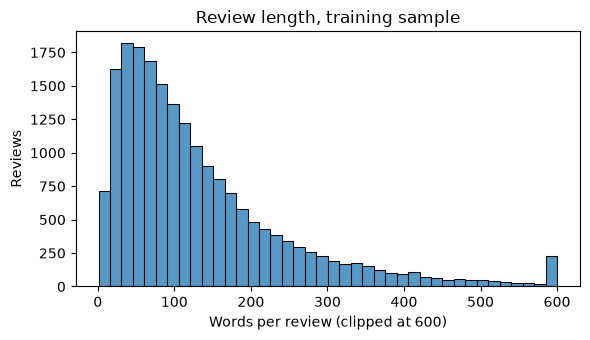

(example reviews not shown: Yelp license)


In [3]:
# Basic inspection: length distribution and a few examples
for d in (df_train, df_val, df_test):
    d["n_words"] = d["text"].str.split().str.len()
print(df_train["n_words"].describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(df_train["n_words"].clip(upper=600), bins=40, ax=ax)
ax.set_xlabel("Words per review (clipped at 600)"); ax.set_ylabel("Reviews"); ax.set_title("Review length, training sample")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_length_distribution.png", dpi=150); plt.show()

for star in range(5):
    print(f"\n[{STAR_NAMES[star]}]", df_train[df_train["label"] == star]["text"].iloc[0][:200].replace("\n", " "))

## 3. Baseline: TF-IDF + logistic regression
A transformer score alone says little. The baseline shows how much the pretrained model adds.

In [4]:
metrics_summary = {}

def metrics_dict(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    gap = np.abs(y_true - y_pred)
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
            "mae_stars": float(gap.mean()),
            "within_one_star": float((gap <= 1).mean())}

t0 = time.time()
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True)
X_train = vec.fit_transform(df_train["text"])
baseline = LogisticRegression(max_iter=1000, C=4.0)
baseline.fit(X_train, df_train["label"])
baseline_pred = baseline.predict(vec.transform(df_test["text"]))
metrics_summary["tfidf_logreg"] = metrics_dict(df_test["label"], baseline_pred)
print(f"Baseline fitted in {time.time() - t0:.0f}s")
print(pd.Series(metrics_summary["tfidf_logreg"]).round(4).to_string())

Baseline fitted in 17s
accuracy           0.5710
macro_f1           0.5701
mae_stars          0.5314
within_one_star    0.9232


## 4. Fine-tune RoBERTa

**Setup:** pretrained `roberta-base` with a new 5-way classification head, maximum length 256 tokens with dynamic padding, AdamW, learning rate 2e-5, weight decay 0.01, linear warmup and decay, batch size 16, 2 epochs, seed 42. The checkpoint with the best validation macro-F1 is kept. bf16 is used only if the GPU supports it.

In [5]:
id2label = {i: STAR_NAMES[i] for i in range(5)}
label2id = {v: k for k, v in id2label.items()}

if DRY_RUN:
    # Tiny random model and a tiny word-level vocabulary so the pipeline can be tested offline.
    from transformers import BertConfig, BertForSequenceClassification, BertTokenizerFast
    words = sorted({w for d in (df_train, df_val, df_test) for t in d["text"] for w in t.lower().split()})
    vocab = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"] + words
    vocab_path = os.path.join(OUT_DIR, "dry_run_vocab.txt")
    with open(vocab_path, "w") as f:
        f.write("\n".join(vocab))
    tokenizer = BertTokenizerFast(vocab_file=vocab_path, do_lower_case=True)
    model = BertForSequenceClassification(BertConfig(
        vocab_size=len(vocab), hidden_size=32, num_hidden_layers=2, num_attention_heads=2,
        intermediate_size=64, max_position_embeddings=MAX_LEN + 8, num_labels=5,
        id2label=id2label, label2id=label2id))
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=5, id2label=id2label, label2id=label2id)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

def to_hf(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True), preserve_index=False)
    return ds.map(tokenize, batched=True, remove_columns=["text"])

ds_train, ds_val, ds_test = to_hf(df_train), to_hf(df_val), to_hf(df_test)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return metrics_dict(labels, np.argmax(logits, axis=-1))

args = TrainingArguments(
    output_dir=os.path.join(OUT_DIR, "checkpoints"),
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=TRAIN_BATCH,
    per_device_eval_batch_size=EVAL_BATCH,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=50,
    seed=SEED,
    bf16=use_bf16,
    report_to="none",
)
trainer = Trainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  data_collator=DataCollatorWithPadding(tokenizer), compute_metrics=compute_metrics)

t0 = time.time()
train_result = trainer.train()
train_minutes = (time.time() - t0) / 60
print(f"Training finished in {train_minutes:.1f} minutes")
print("Validation metrics (best checkpoint):", {k: round(v, 4) for k, v in trainer.evaluate().items() if isinstance(v, float)})

<venv>\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in <home>\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

<venv>\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in <home>\.cache\huggingface\hub\models--FacebookAI--roberta-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training finished in 4.2 minutes


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Mae Stars,Within One Star
0.679486,0.826950,2,0.653000,0.650829,0.379500,0.974000


Validation metrics (best checkpoint): {'eval_loss': 0.827, 'eval_accuracy': 0.653, 'eval_macro_f1': 0.6508, 'eval_mae_stars': 0.3795, 'eval_within_one_star': 0.974}


## 5. Quantitative evaluation on the test subset
Metrics: accuracy, macro-F1 (treats all five stars equally), mean absolute star error (how far off the errors are), and the share of predictions within one star. Because the labels are ordered, the last two matter: predicting 4 stars for a 5-star review is a smaller mistake than predicting 1 star.

In [6]:
pred_out = trainer.predict(ds_test)
logits = pred_out.predictions
probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
rob_pred = probs.argmax(axis=1)
y_true = df_test["label"].to_numpy()
metrics_summary["roberta_base"] = metrics_dict(y_true, rob_pred)

# Bootstrap 95% confidence intervals for macro-F1 (1,000 resamples of the test subset)
def bootstrap_ci(y, p, n_boot=1000, seed=SEED):
    r = np.random.default_rng(seed)
    scores = [f1_score(y[i], p[i], average="macro") for i in (r.integers(0, len(y), len(y)) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])

for key, p in [("tfidf_logreg", baseline_pred), ("roberta_base", rob_pred)]:
    lo, hi = bootstrap_ci(y_true, np.asarray(p))
    metrics_summary[key]["macro_f1_ci95"] = [float(lo), float(hi)]

comparison = pd.DataFrame(metrics_summary).T[["accuracy", "macro_f1", "mae_stars", "within_one_star"]].round(4)
print(comparison.to_string())
print("\nMacro-F1 95% CI:", {k: [round(x, 3) for x in v["macro_f1_ci95"]] for k, v in metrics_summary.items()})
print("\nPer-class report (RoBERTa):")
print(classification_report(y_true, rob_pred, target_names=STAR_NAMES, digits=3, zero_division=0))

             accuracy  macro_f1 mae_stars within_one_star
tfidf_logreg    0.571  0.570133    0.5314          0.9232
roberta_base   0.6606  0.659161     0.369          0.9758

Macro-F1 95% CI: {'tfidf_logreg': [0.557, 0.583], 'roberta_base': [0.646, 0.673]}

Per-class report (RoBERTa):
              precision    recall  f1-score   support

      1 star      0.772     0.755     0.763      1000
     2 stars      0.580     0.635     0.606      1000
     3 stars      0.601     0.532     0.564      1000
     4 stars      0.597     0.578     0.587      1000
     5 stars      0.748     0.803     0.774      1000

    accuracy                          0.661      5000
   macro avg      0.660     0.661     0.659      5000
weighted avg      0.660     0.661     0.659      5000



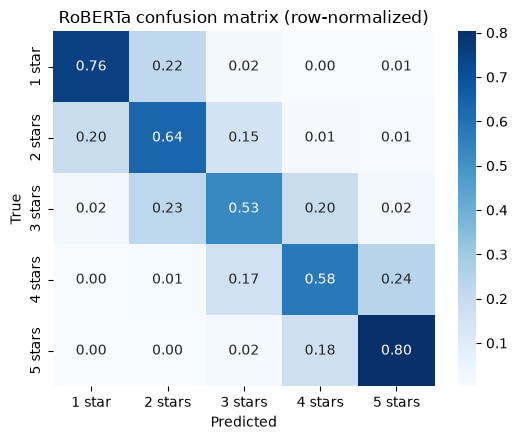

In [7]:
cm = confusion_matrix(y_true, rob_pred, labels=range(5), normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=STAR_NAMES, yticklabels=STAR_NAMES, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("RoBERTa confusion matrix (row-normalized)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_confusion_matrix.png", dpi=150); plt.show()

**Reading the results (seed 42, 5,000 test reviews):**
- RoBERTa reaches 0.661 accuracy and 0.659 macro-F1, against 0.571 and 0.570 for the TF-IDF baseline. The macro-F1 bootstrap intervals do not overlap. Three seeds give RoBERTa accuracy between 0.654 and 0.665.
- The middle ratings are hardest: F1 is 0.564 for 3 stars and 0.587 for 4 stars, against about 0.76 to 0.77 for 1 and 5 stars. The most common confusion is a 4-star review predicted as 5 stars (242 reviews).
- 97.6% of predictions are within one star, and 92.9% of the 1,697 errors are off by exactly one star. Most errors are near misses.
- The intervals cover test-set sampling only, not training variance.

## 6. Error analysis: where does the model struggle?
I add simple linguistic flags to every test review and compare error rates across groups:
- **Length quartile.** Short and long reviews carry different amounts of evidence.
- **Contrast words** (but, however, although, though, yet). Mixed reviews often praise one thing and criticise another, which is a semantics and discourse question.
- **Negation** (not, never, no, n't, nothing). Negation flips the polarity of nearby words.
- **Truncated.** Reviews longer than the 256-token limit lose their ending, and the ending often holds the verdict.

These flags are **keyword heuristics**, not parsed linguistic structure. Group differences are descriptive and do not prove a cause.

**Findings:** reviews with a contrast word are classified correctly 63.3% of the time (n = 3,134) against 70.6% without one (n = 1,866); chi-square = 27.4, p < .001. The gap appears in all four length quartiles. The negation flag covers 76% of reviews, so it is too coarse to interpret (66.0% vs. 66.2%). Truncated reviews score lower (62.8% vs. 66.9%), but truncation overlaps with length.

In [8]:
res = df_test.copy().reset_index(drop=True)
res["review_id"] = np.arange(len(res))
res["true_star"] = res["label"] + 1
res["pred_star"] = rob_pred + 1
res["baseline_star"] = np.asarray(baseline_pred) + 1
res["confidence"] = probs.max(axis=1)
res["abs_err"] = (res["true_star"] - res["pred_star"]).abs()
res["correct"] = (res["abs_err"] == 0).astype(int)

res["length_quartile"] = pd.qcut(res["n_words"].rank(method="first"), 4,
                                 labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"]).astype(str)
res["has_contrast"] = res["text"].str.contains(r"\b(?:but|however|although|though|yet)\b", case=False, regex=True).astype(int)
res["has_negation"] = res["text"].str.contains(r"\b(?:not|never|no|nothing|nobody|none)\b|n't", case=False, regex=True).astype(int)
n_tokens = [len(ids) for ids in tokenizer(res["text"].tolist(), truncation=False)["input_ids"]]
res["n_tokens"] = n_tokens
res["truncated"] = (res["n_tokens"] > MAX_LEN).astype(int)

def seg_table(df, col, label):
    t = df.groupby(col, observed=True).agg(n=("correct", "size"), accuracy=("correct", "mean"),
                                           mean_abs_star_err=("abs_err", "mean")).reset_index()
    t.insert(0, "segment", label)
    return t.rename(columns={col: "group"})

segments = pd.concat([
    seg_table(res, "true_star", "True star rating"),
    seg_table(res, "length_quartile", "Length quartile"),
    seg_table(res.assign(g=res["has_contrast"].map({0: "no contrast word", 1: "has contrast word"})), "g", "Contrast words"),
    seg_table(res.assign(g=res["has_negation"].map({0: "no negation", 1: "has negation"})), "g", "Negation"),
    seg_table(res.assign(g=res["truncated"].map({0: "within limit", 1: "truncated"})), "g", f"Truncated at {MAX_LEN} tokens"),
], ignore_index=True)
segments["accuracy"] = segments["accuracy"].round(3)
segments["mean_abs_star_err"] = segments["mean_abs_star_err"].round(3)
print(segments.to_string(index=False))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (768 > 512). Running this sequence through the model will result in indexing errors


                segment             group    n  accuracy  mean_abs_star_err
       True star rating                 1 1000     0.755              0.283
       True star rating                 2 1000     0.635              0.390
       True star rating                 3 1000     0.532              0.510
       True star rating                 4 1000     0.578              0.437
       True star rating                 5 1000     0.803              0.225
        Length quartile       Q1 shortest 1250     0.650              0.395
        Length quartile                Q2 1250     0.664              0.358
        Length quartile                Q3 1250     0.690              0.325
        Length quartile        Q4 longest 1250     0.638              0.398
         Contrast words has contrast word 3134     0.633              0.395
         Contrast words  no contrast word 1866     0.706              0.325
               Negation      has negation 3818     0.660              0.369
            

length_quartile  has_contrast    n  accuracy
    Q1 shortest             0  889     0.681
    Q1 shortest             1  361     0.576
             Q2             0  561     0.706
             Q2             1  689     0.630
             Q3             0  307     0.769
             Q3             1  943     0.665
     Q4 longest             0  109     0.743
     Q4 longest             1 1141     0.628
has_contrast: accuracy 0.706 (no) vs 0.633 (yes), chi-square p = 0.0000
has_negation: accuracy 0.662 (no) vs 0.660 (yes), chi-square p = 0.9065
truncated: accuracy 0.669 (no) vs 0.628 (yes), chi-square p = 0.0171

Share of predictions by star distance: {0: 0.661, 1: 0.315, 2: 0.02, 3: 0.003, 4: 0.001}
Of all errors, 92.9% are off by exactly one star.


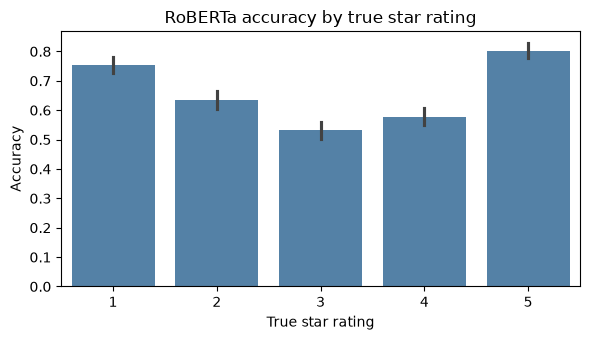

In [9]:
# Contrast words vs. length: compare within length quartiles so length does not drive the result
cross = (res.groupby(["length_quartile", "has_contrast"], observed=True)
            .agg(n=("correct", "size"), accuracy=("correct", "mean")).round(3).reset_index())
print(cross.to_string(index=False))

for flag in ["has_contrast", "has_negation", "truncated"]:
    table = pd.crosstab(res[flag], res["correct"])
    if table.shape == (2, 2):
        chi2, p, _, _ = chi2_contingency(table)
        print(f"{flag}: accuracy {res[res[flag]==0]['correct'].mean():.3f} (no) vs {res[res[flag]==1]['correct'].mean():.3f} (yes), chi-square p = {p:.4f}")

dist = res["abs_err"].value_counts(normalize=True).sort_index().round(3)
print("\nShare of predictions by star distance:", dist.to_dict())
errors_only = res[res["correct"] == 0]
print(f"Of all errors, {(errors_only['abs_err'] == 1).mean():.1%} are off by exactly one star.")

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.barplot(data=res, x="true_star", y="correct", errorbar=("ci", 95), color="steelblue", ax=ax)
ax.set_xlabel("True star rating"); ax.set_ylabel("Accuracy"); ax.set_title("RoBERTa accuracy by true star rating")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_accuracy_by_star.png", dpi=150); plt.show()

## 7. Manual error review sample
Quantitative flags only go so far. This cell exports up to 30 errors (10 far misses of two or more stars, 10 adjacent-star errors, 10 high-confidence errors) to a CSV for hand coding. The sample is deliberately not representative of all errors, so counts from it must not be read as shares of all 1,697 errors.

In my hand coding of the 30 sampled errors: 11 one-star boundary cases with clearly positive or negative text, 8 mixed positive and negative points, 4 where the label did not fit the text, 3 sarcasm or informal style, 2 cut at 256 tokens, and 2 non-English. The CSV contains review text, so it stays out of the repository.

In [10]:
def take(df, n):
    return df.sample(n=min(n, len(df)), random_state=SEED) if len(df) else df

far = take(errors_only[errors_only["abs_err"] >= 2], 10)
adjacent = take(errors_only[errors_only["abs_err"] == 1], 10)
confident = errors_only.sort_values("confidence", ascending=False).head(10)
review = (pd.concat([far.assign(reason="far miss"), adjacent.assign(reason="adjacent error"),
                     confident.assign(reason="high confidence")])
            .drop_duplicates("review_id")
            [["review_id", "reason", "true_star", "pred_star", "confidence", "has_contrast", "has_negation", "truncated", "text"]])
review["my_category"] = ""
review["my_note"] = ""
review.to_csv(f"{OUT_DIR}/manual_error_review.csv", index=False)
print(f"Wrote {len(review)} errors to {OUT_DIR}/manual_error_review.csv")
for _, r in review.head(5).iterrows():
    print(f"\n[{r['reason']}] true {r['true_star']} / predicted {r['pred_star']} / confidence {r['confidence']:.2f}\n{r['text'][:300]}")

Wrote 30 errors to outputs/manual_error_review.csv
(review text not shown: Yelp license)


## 8. SQL layer and dashboard export (analyst portfolio piece)
The predictions go into a SQLite table. The queries below answer the questions a stakeholder would ask: where is the model weakest, which mistakes are the most costly, and which reviews should a human read. The final cell writes a tidy CSV that can be loaded into Looker Studio or Tableau Public for a one-page dashboard.

In [11]:
db_path = os.path.join(OUT_DIR, "yelp_predictions.db")
if os.path.exists(db_path):
    os.remove(db_path)
con = sqlite3.connect(db_path)
res.drop(columns=["label"]).to_sql("predictions", con, index=False)

def q(sql):
    return pd.read_sql_query(sql, con)

print("1) Accuracy and average star error by true rating")
print(q('''SELECT true_star, COUNT(*) AS n, ROUND(AVG(correct), 3) AS accuracy, ROUND(AVG(abs_err), 3) AS mean_abs_err
           FROM predictions GROUP BY true_star ORDER BY true_star''').to_string(index=False))

print("\n2) Most common confusions")
print(q('''SELECT true_star, pred_star, COUNT(*) AS n FROM predictions
           WHERE correct = 0 GROUP BY true_star, pred_star ORDER BY n DESC LIMIT 8''').to_string(index=False))

print("\n3) Contrast words by length quartile")
print(q('''SELECT length_quartile, has_contrast, COUNT(*) AS n, ROUND(AVG(correct), 3) AS accuracy
           FROM predictions GROUP BY length_quartile, has_contrast ORDER BY length_quartile, has_contrast''').to_string(index=False))

print("\n4) Two most confident mistakes per true rating (window function)")
print(q('''SELECT true_star, pred_star, ROUND(confidence, 3) AS confidence, SUBSTR(text, 1, 100) AS text_start FROM (
             SELECT *, ROW_NUMBER() OVER (PARTITION BY true_star ORDER BY confidence DESC) AS rn
             FROM predictions WHERE correct = 0)
           WHERE rn <= 2 ORDER BY true_star, rn''').to_string(index=False))
con.close()

1) Accuracy and average star error by true rating
 true_star    n  accuracy  mean_abs_err
         1 1000     0.755         0.283
         2 1000     0.635         0.390
         3 1000     0.532         0.510
         4 1000     0.578         0.437
         5 1000     0.803         0.225

2) Most common confusions
 true_star  pred_star   n
         4          5 242
         3          2 227
         1          2 219
         3          4 199
         2          1 195
         5          4 176
         4          3 167
         2          3 151

3) Contrast words by length quartile
length_quartile  has_contrast    n  accuracy
    Q1 shortest             0  889     0.681
    Q1 shortest             1  361     0.576
             Q2             0  561     0.706
             Q2             1  689     0.630
             Q3             0  307     0.769
             Q3             1  943     0.665
     Q4 longest             0  109     0.743
     Q4 longest             1 1141     0.628

4) Tw

In [12]:
segments.to_csv(f"{OUT_DIR}/dashboard_error_by_segment.csv", index=False)
res.drop(columns=["label"]).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)
print("Wrote dashboard_error_by_segment.csv and test_predictions.csv to", OUT_DIR)

Wrote dashboard_error_by_segment.csv and test_predictions.csv to outputs


## 9. Limitations and ethical considerations
- **Label noise and subjectivity.** A star rating is a noisy proxy for the text. In the hand-coded sample, many errors were one-star boundary cases where the text was clearly positive or negative, so part of the error is disagreement over where one rating ends and the next begins.
- **Domain and population bias.** Yelp reviews cover specific businesses, cities, and reviewer types. The model reads English only, and the sample included French and German reviews that it misjudged. Results do not transfer to other review sources or languages.
- **Truncation.** Reviews over 256 tokens lose their ending. Truncated reviews scored lower, but the effect overlaps with length.
- **Subset evaluation and keyword flags.** The test set is a 5,000-review subset, and the linguistic flags are keyword rules, not parses.
- **Privacy and terms.** Reviews are user-written text and can mention names or places. The Hugging Face card lists the Yelp license as "other", so this repository holds no review text and the data should be reused only within Yelp's terms.
- **Misuse.** Star predictions could be used to rank businesses or flag reviewers automatically. A person should stay in the loop for low-confidence predictions, and the model should not drive decisions about individuals.

## 10. Open research question
Does scoring each clause of a review separately, then combining the scores, reduce the accuracy gap on reviews that contain contrast words? A contrast marker joins clauses that often point in opposite directions, so the overall rating depends on how the clauses are weighted. This is not implemented here. Two other directions follow from the results: ordinal regression (most errors are near misses) and head-and-tail truncation for long reviews.

## 11. Reproducibility record

In [13]:
record = {
    "seed": SEED, "dry_run": DRY_RUN, "model": MODEL_NAME, "max_len": MAX_LEN, "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE, "train_batch": TRAIN_BATCH,
    "n_train": len(df_train), "n_val": len(df_val), "n_test": len(df_test),
    "train_minutes": round(train_minutes, 2),
    "metrics": metrics_summary,
    "transformers": transformers.__version__, "torch": torch.__version__,
    "gpu": torch.cuda.get_device_name(0) if use_cuda else "none",
    "python": platform.python_version(),
}
with open(os.path.join(OUT_DIR, "run_record.json"), "w") as f:
    json.dump(record, f, indent=2)
print(json.dumps(record, indent=2))

{
  "seed": 42,
  "dry_run": false,
  "model": "FacebookAI/roberta-base",
  "max_len": 256,
  "epochs": 2,
  "learning_rate": 2e-05,
  "train_batch": 16,
  "n_train": 20000,
  "n_val": 2000,
  "n_test": 5000,
  "train_minutes": 4.24,
  "metrics": {
    "tfidf_logreg": {
      "accuracy": 0.571,
      "macro_f1": 0.5701331284786948,
      "mae_stars": 0.5314,
      "within_one_star": 0.9232,
      "macro_f1_ci95": [
        0.5571252549012726,
        0.5834730304638743
      ]
    },
    "roberta_base": {
      "accuracy": 0.6606,
      "macro_f1": 0.6591612625959807,
      "mae_stars": 0.369,
      "within_one_star": 0.9758,
      "macro_f1_ci95": [
        0.645555185798523,
        0.6725934560508028
      ]
    }
  },
  "transformers": "5.23.0",
  "torch": "2.11.0+cu128",
  "gpu": "NVIDIA GeForce RTX 5070 Ti Laptop GPU",
  "python": "3.12.10"
}


## References
- Hugging Face. (n.d.). *Yelp/yelp_review_full* [Dataset card]. https://huggingface.co/datasets/Yelp/yelp_review_full. The card cites Zhang et al. (2015), "Character-level convolutional networks for text classification."
- Liu, Y., Ott, M., Goyal, N., Du, J., Joshi, M., Chen, D., Levy, O., Lewis, M., Zettlemoyer, L., & Stoyanov, V. (2019). *RoBERTa: A robustly optimized BERT pretraining approach*. arXiv:1907.11692.
- Wolf, T., et al. (2020). Transformers: State-of-the-art natural language processing. *Proceedings of EMNLP 2020: System Demonstrations*, 38-45.